# Projet IA : Modélisation de la séparation thermodynamique
## Partie 1 : Préparation et exploration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1.1 Charger le fichier
# Note: On utilise glob pour trouver le fichier CSV car le nom contient des caractères spéciaux
import glob
csv_files = glob.glob('*.csv')
if csv_files:
    df = pd.read_csv(csv_files[0])
    print(f"Fichier chargé : {csv_files[0]}")
else:
    print("Aucun fichier CSV trouvé !")
df.head()

Fichier chargé : Fichier csv base des donnés .csv


,Temp_Plateau,Debit_Reflux,Debit_Strippage,Densite_Brut,Point_de_Trouble,Conformite
0,263.12,82.45,1.45,0.835,2.35,1.0
1,274.56,76.12,1.68,0.848,8.12,0.0
2,527.70,88.34,1.35,0.832,1.18,1.0
3,258.45,79.10,1.52,0.840,1.95,1.0
4,530.00,81.56,1.62,0.843,4.45,0.0


In [2]:
# 1.2 Vérification des données
print("Valeurs manquantes :")
print(df.isnull().sum())

Valeurs manquantes :
Temp_Plateau        0
Debit_Reflux        0
Debit_Strippage     0
Densite_Brut        0
Point_de_Trouble    0
Conformite          0
dtype: int64


In [3]:
# 1.3 Statistiques descriptives
df.describe()

,Temp_Plateau,Debit_Reflux,Debit_Strippage,Densite_Brut,Point_de_Trouble,Conformite
count,209.00000,209.000000,209.000000,209.000000,209.000000,209.000000
mean,534.33244,6.327321,125.606411,2.770335,4.168900,0.956938
std,61.84133,17.245087,36.186795,8.718480,18.290339,0.203485
min,258.45000,1.000000,1.280000,0.100000,0.000000,0.000000
25%,519.80000,1.200000,103.700000,0.600000,0.000000,1.000000
50%,527.70000,1.500000,145.800000,1.300000,0.000000,1.000000
75%,578.30000,3.000000,150.400000,1.500000,1.000000,1.000000
max,599.90000,88.340000,159.500000,49.600000,98.800000,1.000000


## Partie 2 : Analyse des corrélations et nettoyage

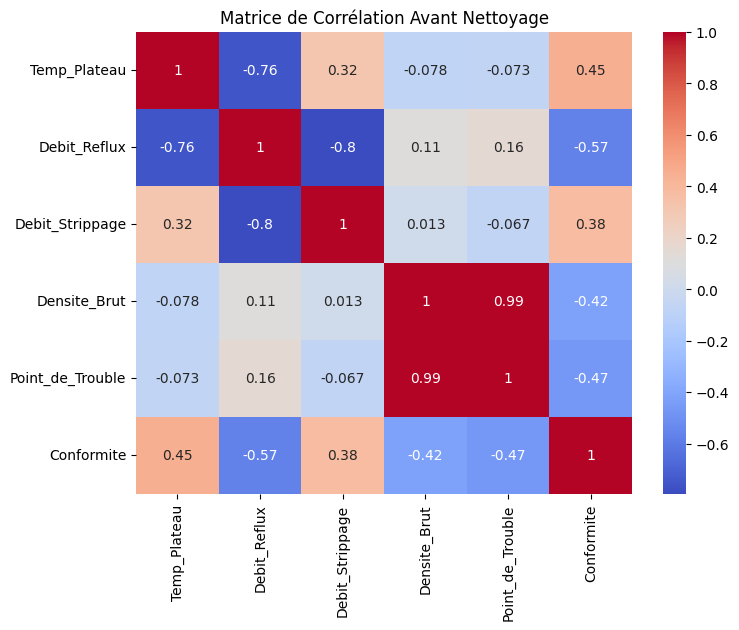

In [4]:
# 2.1 Analyse de la matrice de corrélation (Heat Map)
corr = df.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Matrice de Corrélation Avant Nettoyage")
plt.show()

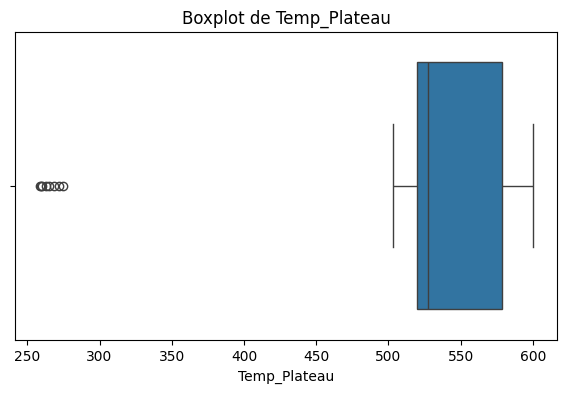

In [5]:
# 2.2 Analyse statistique des variables (Box Plot pour Temp_Plateau)
plt.figure(figsize=(7,4))
sns.boxplot(x=df["Temp_Plateau"])
plt.title("Boxplot de Temp_Plateau")
plt.show()

In [6]:
# 2.3 Nettoyage du jeu de données (Suppression des valeurs aberrantes)
# On observe des valeurs de Temp_Plateau très basses (< 300) qui s'écartent de la majorité (> 500)
df_clean = df[df["Temp_Plateau"] > 500].copy()
print(f"Ancienne taille: {len(df)}, Nouvelle taille: {len(df_clean)}")

Ancienne taille: 209, Nouvelle taille: 201


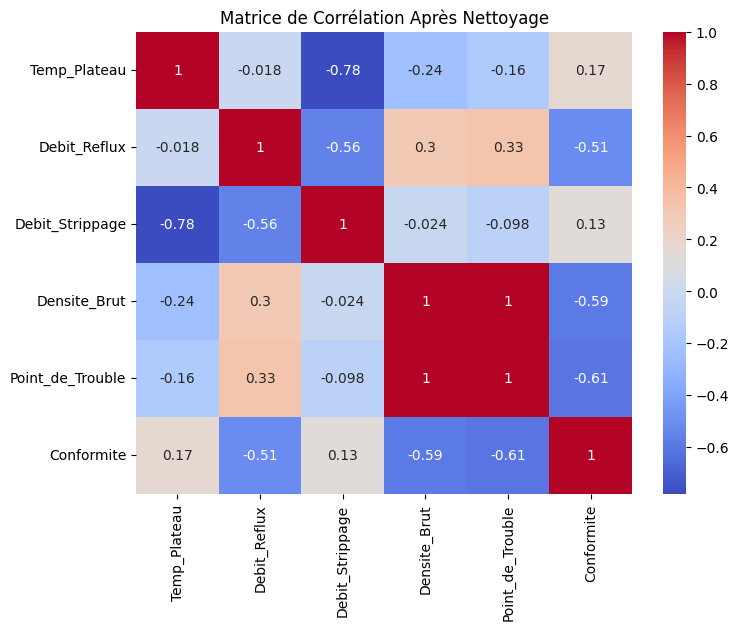

In [7]:
# 2.4 Analyse comparative de la matrice de corrélation après nettoyage
corr_clean = df_clean.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_clean, annot=True, cmap="coolwarm")
plt.title("Matrice de Corrélation Après Nettoyage")
plt.show()

## Partie 3 : Modélisation (Régression Linéaire)

In [8]:
# 3.1 Séparation des variables
X = df_clean[["Temp_Plateau", "Debit_Reflux", "Debit_Strippage", "Densite_Brut"]]
y = df_clean["Point_de_Trouble"]

# 3.2 Séparation en Training Set et Test Set
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3.3 Construire et entraîner le modèle
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [9]:
# 3.4 Affichage des coefficients et équation
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [0.06931153 0.09979375 0.03064562 2.11383325]
Intercept: -43.95571607247533


In [10]:
# 3.5 Prédiction sur l'ensemble de test
y_pred = model.predict(X_test)

## Partie 4 : Évaluation et Visualisation

In [11]:
# 4.1 Évaluation du modèle
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MAE = mean_absolute_error(y_test, y_pred)
MSE = mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
R2 = r2_score(y_test, y_pred)

print(f"MAE: {MAE:.4f}")
print(f"MSE: {MSE:.4f}")
print(f"RMSE: {RMSE:.4f}")
print(f"R2: {R2:.4f}")

MAE: 0.2321
MSE: 0.2036
RMSE: 0.4512
R2: 0.9990


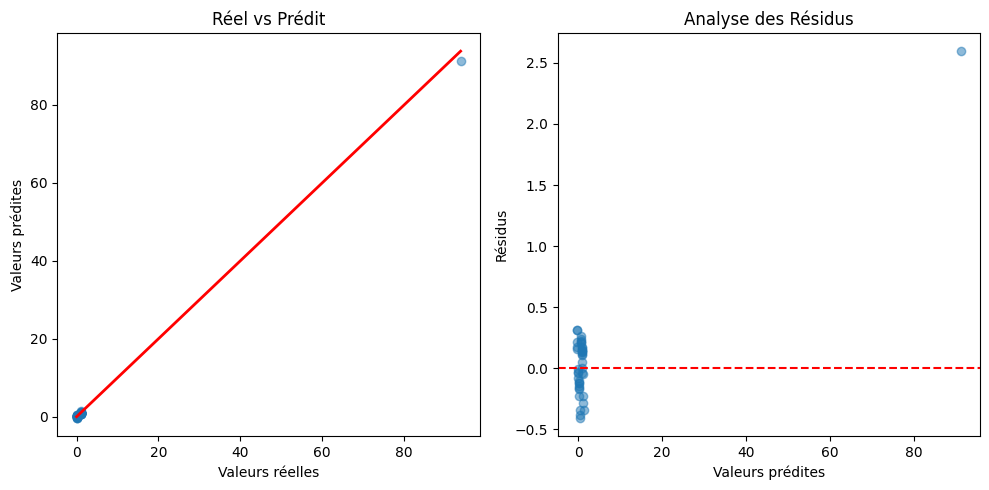

In [12]:
# 4.2 Visualisation des prédictions et résidus
plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Réel vs Prédit")

plt.subplot(1, 2, 2)
residuals = y_test - y_pred
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Valeurs prédites")
plt.ylabel("Résidus")
plt.title("Analyse des Résidus")

plt.tight_layout()
plt.show()

## Partie 5 : Classification (SVM)

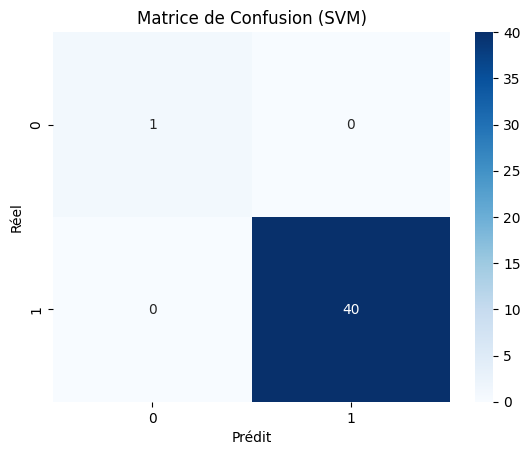

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00        40

    accuracy                           1.00        41
   macro avg       1.00      1.00      1.00        41
weighted avg       1.00      1.00      1.00        41



In [13]:
# 5.1 Création de la variable cible Qualité (Conforme si Point_de_Trouble <= 3)
df_clean["Qualite"] = (df_clean["Point_de_Trouble"] <= 3).astype(int)

# 5.2 Préparation des données pour la classification
X_class = df_clean[["Temp_Plateau", "Debit_Reflux", "Debit_Strippage", "Densite_Brut"]]
y_class = df_clean["Qualite"]
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_class, y_class, test_size=0.2, random_state=42)

# 5.3 Entraînement du modèle SVM
from sklearn.svm import SVC
svm_model = SVC(kernel='linear')
svm_model.fit(X_train_c, y_train_c)

# 5.4 Évaluation (Matrice de Confusion)
from sklearn.metrics import confusion_matrix, classification_report
y_pred_c = svm_model.predict(X_test_c)

cm = confusion_matrix(y_test_c, y_pred_c)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.title('Matrice de Confusion (SVM)')
plt.show()

print(classification_report(y_test_c, y_pred_c))

## Partie 6 : Application Industrielle
Prédiction pour de nouvelles données opérationnelles.

In [14]:
new_data = pd.DataFrame({
    "Temp_Plateau": [265],
    "Debit_Reflux": [80],
    "Debit_Strippage": [1.5],
    "Densite_Brut": [0.840]
})

prediction_pt = model.predict(new_data)
prediction_qual = svm_model.predict(new_data)

print(f"Point de Trouble Prédit : {prediction_pt[0]:.2f} °C")
print(f"Qualité Prédite : {'Conforme' if prediction_qual[0] == 1 else 'Non Conforme'}")

Point de Trouble Prédit : -15.78 °C
Qualité Prédite : Non Conforme
